## 1. Imports and Project Paths

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

cwd = Path.cwd()

# If running from src or notebooks, move one level up
if cwd.name in ["src", "notebooks"]:
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "m5_sales_sample.parquet"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "m5_features.parquet"

print("Project root:", PROJECT_ROOT)
print("Input exists:", INPUT_PATH.exists())
print("Input path:", INPUT_PATH)

Project root: c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting
Input exists: True
Input path: c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\m5_sales_sample.parquet


## 2. Load the Preprocessed Dataset

In [3]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {INPUT_PATH}. Check that preprocessing.py has been run "
        "and that this notebook is opened from the project root or notebooks/."
    )

data = pd.read_parquet(INPUT_PATH)

print("Shape:", data.shape)
print("Unique products:", data["item_id"].nunique())
print("Unique stores:", data["store_id"].nunique())
print("Date range:", data["date"].min(), "to", data["date"].max())

display(data.head())


Shape: (382600, 25)
Unique products: 20
Unique stores: 10
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price,price_missing,data_source,source_record_id
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,NaN,NaN,NaN,0,0,0,NaN,1,M5,HOBBIES_1_001_CA_1_validation_d_1
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,NaN,NaN,NaN,0,0,0,NaN,1,M5,HOBBIES_1_001_CA_1_validation_d_2
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,NaN,NaN,NaN,0,0,0,NaN,1,M5,HOBBIES_1_001_CA_1_validation_d_3
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,2011-02-01,11101,...,NaN,NaN,NaN,1,1,0,NaN,1,M5,HOBBIES_1_001_CA_1_validation_d_4
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,2011-02-02,11101,...,NaN,NaN,NaN,1,0,1,NaN,1,M5,HOBBIES_1_001_CA_1_validation_d_5


## 3. Inspect a Single Product-Store Time Series

In [5]:
example_item = data["item_id"].iloc[0]
example_store = data.loc[data["item_id"] == example_item, "store_id"].iloc[0]

sample = (
    data.loc[
        (data["item_id"] == example_item) &
        (data["store_id"] == example_store),
        ["date", "sales", "sell_price", "price_missing"]
    ]
    .sort_values("date")
    .copy()
)

print("Product:", example_item)
print("Store:", example_store)
display(sample.head(12))


Product: HOBBIES_1_001
Store: CA_1


,date,sales,sell_price,price_missing
0,2011-01-29,0,NaN,1
1,2011-01-30,0,NaN,1
2,2011-01-31,0,NaN,1
3,2011-02-01,0,NaN,1
4,2011-02-02,0,NaN,1
5,2011-02-03,0,NaN,1
6,2011-02-04,0,NaN,1
7,2011-02-05,0,NaN,1
8,2011-02-06,0,NaN,1
9,2011-02-07,0,NaN,1


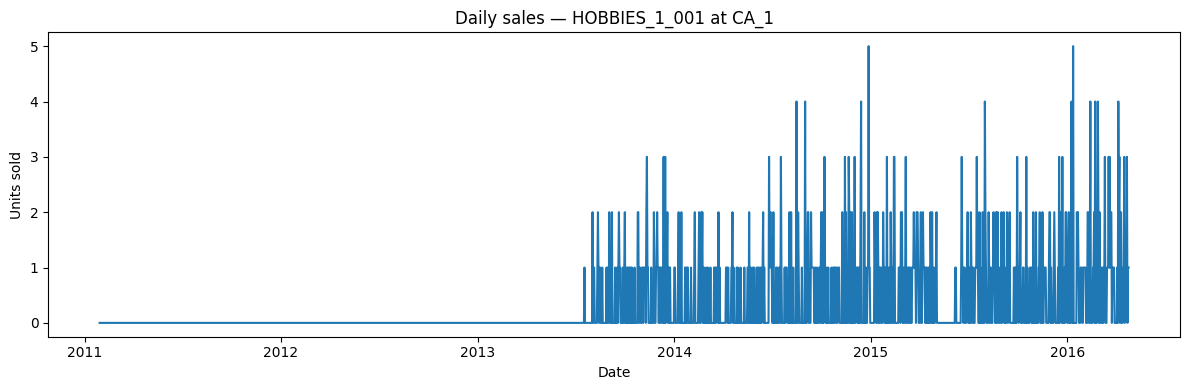

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(sample["date"], sample["sales"])
plt.title(f"Daily sales — {example_item} at {example_store}")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()


## 4. Understand Rolling Averages

A rolling average smooths short-term variation.

We shift sales by one day before calculating the rolling average. This is essential: the feature for a given date must not include that date's actual sales, because that is the value we want the model to predict.

- `rolling_mean_7`: Mean of the previous 7 days.
- `rolling_mean_28`: Mean of the previous 28 days.

We require a complete window (`min_periods` equals the window size), so early rows remain missing until enough history exists.

In [7]:
sample_rolling = sample[["date", "sales"]].copy()
previous_sales = sample_rolling["sales"].shift(1)
sample_rolling["rolling_mean_7"] = previous_sales.rolling(
    window=7, min_periods=7
).mean()
sample_rolling["rolling_mean_28"] = previous_sales.rolling(
    window=28, min_periods=28
).mean()

display(sample_rolling.head(35))


,date,sales,rolling_mean_7,rolling_mean_28
0,2011-01-29,0,NaN,NaN
1,2011-01-30,0,NaN,NaN
2,2011-01-31,0,NaN,NaN
3,2011-02-01,0,NaN,NaN
4,2011-02-02,0,NaN,NaN
5,2011-02-03,0,NaN,NaN
6,2011-02-04,0,NaN,NaN
7,2011-02-05,0,0.0,NaN
8,2011-02-06,0,0.0,NaN
9,2011-02-07,0,0.0,NaN


## 5. Create Features for Every Product-Store Series

Now apply the same calculations separately to each `(item_id, store_id)` group. Grouping is important: one product's history must never leak into another product's features, and one store's history must never leak into another store's features.

In [8]:
def create_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Create leakage-safe time-series features per product and store."""

    required_columns = {
        "item_id", "store_id", "state_id", "date", "sales",
        "sell_price", "price_missing",
        "snap_CA", "snap_TX", "snap_WI"
    }
    missing_columns = required_columns.difference(frame.columns)
    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"])

    group_columns = ["item_id", "store_id"]
    result = result.sort_values(group_columns + ["date"]).reset_index(drop=True)

    # Calendar features
    result["day_of_week"] = result["date"].dt.dayofweek
    result["month"] = result["date"].dt.month
    result["is_weekend"] = (result["day_of_week"] >= 5).astype("int8")

    # Historical sales features, calculated within each product-store series
    sales_by_group = result.groupby(group_columns, sort=False)["sales"]

    result["lag_1"] = sales_by_group.shift(1)
    result["lag_7"] = sales_by_group.shift(7)

    result["rolling_mean_7"] = sales_by_group.transform(
        lambda values: values.shift(1).rolling(window=7, min_periods=7).mean()
    )
    result["rolling_mean_28"] = sales_by_group.transform(
        lambda values: values.shift(1).rolling(window=28, min_periods=28).mean()
    )

    # Pick the SNAP indicator corresponding to the store's state
    snap_by_state = {
        "CA": "snap_CA",
        "TX": "snap_TX",
        "WI": "snap_WI",
    }

    result["snap"] = 0
    for state, source_column in snap_by_state.items():
        state_mask = result["state_id"].eq(state)
        result.loc[state_mask, "snap"] = result.loc[state_mask, source_column]

    # Keep identifiers, target, and engineered features.
    # The target 'sales' is retained for training labels, not used as a same-day input.
    feature_columns = [
        "item_id",
        "store_id",
        "date",
        "sales",
        "day_of_week",
        "is_weekend",
        "month",
        "sell_price",
        "price_missing",
        "snap",
        "lag_1",
        "lag_7",
        "rolling_mean_7",
        "rolling_mean_28",
    ]

    return result[feature_columns].copy()


## 6. Run Feature Engineering

This creates the engineered dataset in memory. We will inspect it before saving.

In [9]:
features = create_features(data)

print("Engineered shape:", features.shape)
print("Columns:", features.columns.tolist())
display(features.head(12))

Engineered shape: (382600, 14)
Columns: ['item_id', 'store_id', 'date', 'sales', 'day_of_week', 'is_weekend', 'month', 'sell_price', 'price_missing', 'snap', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_28']


,item_id,store_id,date,sales,day_of_week,is_weekend,month,sell_price,price_missing,snap,lag_1,lag_7,rolling_mean_7,rolling_mean_28
0,HOBBIES_1_001,CA_1,2011-01-29,0,5,1,1,NaN,1,0,NaN,NaN,NaN,NaN
1,HOBBIES_1_001,CA_1,2011-01-30,0,6,1,1,NaN,1,0,0.0,NaN,NaN,NaN
2,HOBBIES_1_001,CA_1,2011-01-31,0,0,0,1,NaN,1,0,0.0,NaN,NaN,NaN
3,HOBBIES_1_001,CA_1,2011-02-01,0,1,0,2,NaN,1,1,0.0,NaN,NaN,NaN
4,HOBBIES_1_001,CA_1,2011-02-02,0,2,0,2,NaN,1,1,0.0,NaN,NaN,NaN
5,HOBBIES_1_001,CA_1,2011-02-03,0,3,0,2,NaN,1,1,0.0,NaN,NaN,NaN
6,HOBBIES_1_001,CA_1,2011-02-04,0,4,0,2,NaN,1,1,0.0,NaN,NaN,NaN
7,HOBBIES_1_001,CA_1,2011-02-05,0,5,1,2,NaN,1,1,0.0,0.0,0.0,NaN
8,HOBBIES_1_001,CA_1,2011-02-06,0,6,1,2,NaN,1,1,0.0,0.0,0.0,NaN
9,HOBBIES_1_001,CA_1,2011-02-07,0,0,0,2,NaN,1,1,0.0,0.0,0.0,NaN


## 7. Inspect Missing Values

Missing lag and rolling values at the beginning of each series are expected. For example, a 28-day rolling average cannot be calculated until 28 previous observations are available.

Do not automatically fill these values with zero. We'll decide how to handle the initial history rows when we prepare the model's training examples.

In [10]:
missing_summary = (
    features.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)
missing_summary["missing_percentage"] = (
    missing_summary["missing_count"] / len(features) * 100
).round(2)

display(missing_summary)


,missing_count,missing_percentage
item_id,0,0.00
store_id,0,0.00
date,0,0.00
sales,0,0.00
day_of_week,0,0.00
is_weekend,0,0.00
month,0,0.00
sell_price,58317,15.24
price_missing,0,0.00
snap,0,0.00


## 8. Validate the Calculations

These checks help catch common time-series mistakes:

1. There should be one row per product, store, and date.
2. The first row in each product-store series should not have `lag_1`.
3. For a given row, `lag_1` should equal the previous day's sales in that same series.
4. Rolling features must be based only on earlier observations.

In [11]:
# Check for duplicate product-store-date records
duplicate_count = features.duplicated(
    subset=["item_id", "store_id", "date"]
).sum()

# Check the first row of each product-store series
first_rows = features.groupby(
    ["item_id", "store_id"], sort=False
).head(1)

# Verify lag_1 against the previous observation in each series
check = data.sort_values(
    ["item_id", "store_id", "date"]
).copy()
check["expected_lag_1"] = check.groupby(
    ["item_id", "store_id"], sort=False
)["sales"].shift(1)

lag_check = features.merge(
    check[["item_id", "store_id", "date", "expected_lag_1"]],
    on=["item_id", "store_id", "date"],
    how="left",
    validate="one_to_one"
)

lag_mismatches = (
    lag_check["lag_1"].fillna(-999999)
    != lag_check["expected_lag_1"].fillna(-999999)
).sum()

print("Duplicate product-store-date rows:", duplicate_count)
print("Product-store series:", features.groupby(["item_id", "store_id"]).ngroups)
print("First rows with missing lag_1:", first_rows["lag_1"].isna().sum())
print("lag_1 mismatches:", lag_mismatches)

assert duplicate_count == 0
assert lag_mismatches == 0
assert first_rows["lag_1"].isna().all()

print("\nAll validation checks passed.")


Duplicate product-store-date rows: 0
Product-store series: 200
First rows with missing lag_1: 200
lag_1 mismatches: 0

All validation checks passed.


## 9. Visualise Actual Sales and Rolling Average

The rolling average should follow the broad direction of sales while smoothing daily fluctuations. The rolling average is shifted, so it represents information available before each date.

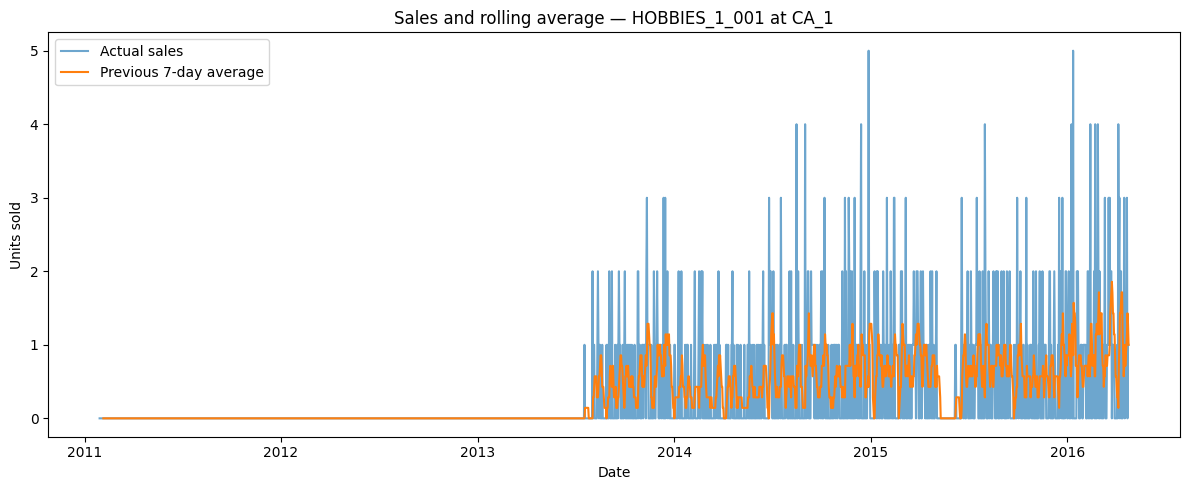

In [12]:
plot_data = features.loc[
    (features["item_id"] == example_item) &
    (features["store_id"] == example_store)
].sort_values("date")

plt.figure(figsize=(12, 5))
plt.plot(plot_data["date"], plot_data["sales"], label="Actual sales", alpha=0.65)
plt.plot(plot_data["date"], plot_data["rolling_mean_7"], label="Previous 7-day average")
plt.title(f"Sales and rolling average — {example_item} at {example_store}")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.legend()
plt.tight_layout()
plt.show()


## 10. Save the Engineered Dataset

The resulting Parquet file will be used in the next stage: chronological train/validation/test splitting and model training.

In [13]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
features.to_parquet(OUTPUT_PATH, index=False)

print("Saved:", OUTPUT_PATH)
print("Final shape:", features.shape)


Saved: c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\m5_features.parquet
Final shape: (382600, 14)


In [14]:
print("Missing price analysis:")

print(
    features.groupby("price_missing")["sales"]
    .agg(["count", "mean", "sum", "min", "max"])
)

print("\nMissing price percentage:")
print(features["price_missing"].mean() * 100)

Missing price analysis:
                count      mean     sum  min  max
price_missing                                    
0              324283  1.429998  463724    0   93
1               58317  0.000000       0    0    0

Missing price percentage:
15.242289597490851


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

# Paths
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name in {"src", "notebooks"} else cwd
DATA_DIR = PROJECT_ROOT / "data" / "processed"

# 1. Load contiguous historical data (before splitting)
source_file = DATA_DIR / "m5_features.parquet"
if not source_file.exists():
    source_file = DATA_DIR / "m5_sales_sample.parquet"

df = pd.read_parquet(source_file)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["item_id", "store_id", "date"]).reset_index(drop=True)

# 2. Compute Direct 5-Day Forward Target: sum(t+1 .. t+5)
HORIZON = 5
df["target_5d"] = (
    df.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.iloc[::-1].rolling(HORIZON, min_periods=HORIZON).sum().iloc[::-1].shift(-1))
)

# 3. Compute Leakage-Free Features (strictly available at decision day t0)
# Day t0 actual sales
df["lag_0"] = df["sales"]
df["lag_7"] = df.groupby(["item_id", "store_id"])["sales"].shift(7)
df["lag_14"] = df.groupby(["item_id", "store_id"])["sales"].shift(14)

# Past cumulative consumption ending at t0
df["hist_sum_5d"] = (
    df.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.rolling(HORIZON, min_periods=HORIZON).sum())
)
df["hist_mean_7d"] = (
    df.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)
df["hist_mean_28d"] = (
    df.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.rolling(28, min_periods=14).mean())
)

# 4. Seasonal Naïve 5-Day Baseline: past 5-day sum shifted by 7 days
df["seasonal_naive_5d"] = df.groupby(["item_id", "store_id"])["hist_sum_5d"].shift(7)

# 5. Drop unneeded 1-day rolling columns if present
cols_to_drop = [c for c in ["lag_1", "rolling_mean_7", "rolling_mean_28"] if c in df.columns]
df = df.drop(columns=cols_to_drop)

# Save full processed dataset
df.to_parquet(DATA_DIR / "m5_features_5d.parquet", index=False)

# 6. Apply Chronological Splits
# Drop warmup rows where 28-day history or forward target is unavailable
clean_df = df.dropna(subset=["target_5d", "seasonal_naive_5d", "hist_mean_28d"]).copy()

TRAIN_END = "2015-04-13"
VAL_START = "2015-04-14"
VAL_END = "2015-10-18"
TEST_START = "2015-10-19"

train_5d = clean_df[clean_df["date"] <= TRAIN_END].copy()
val_5d = clean_df[(clean_df["date"] >= VAL_START) & (clean_df["date"] <= VAL_END)].copy()
test_5d = clean_df[clean_df["date"] >= TEST_START].copy()

# Save split parquets
train_5d.to_parquet(DATA_DIR / "train_5d.parquet", index=False)
val_5d.to_parquet(DATA_DIR / "validation_5d.parquet", index=False)
test_5d.to_parquet(DATA_DIR / "test_5d.parquet", index=False)

# 7. Write updated metadata JSON
meta_5d = {
    "input_file": "m5_features_5d.parquet",
    "target": "target_5d",
    "horizon_days": 5,
    "feature_columns": [
        "item_id", "store_id", "day_of_week", "is_weekend", "month",
        "sell_price", "price_missing", "snap", "lag_0", "lag_7", "lag_14",
        "hist_sum_5d", "hist_mean_7d", "hist_mean_28d"
    ],
    "baseline_column": "seasonal_naive_5d",
    "identifier_columns": ["item_id", "store_id", "date"],
    "train_rows": len(train_5d),
    "val_rows": len(val_5d),
    "test_rows": len(test_5d)
}

with open(DATA_DIR / "split_metadata_5d.json", "w") as f:
    json.dump(meta_5d, f, indent=2)

print("Saved new 5-day parquet files and split_metadata_5d.json.")

Saved new 5-day parquet files and split_metadata_5d.json.
